In [1]:
#Loading the data
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("telco_cleaned.csv")

# Churn as a number: 1 = Yes, 0 = No (makes churn-rate math easy)
df["churn_flag"] = (df["churn"] == "Yes").astype(int)

# Same tenure groups as Task 4
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 36, 72],
                            labels=["0-12 months", "13-36 months", "37+ months"])
df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn,churn_flag,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,0,13-36 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,37+ months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,0-12 months


### Part A: Grouping by tenure (statistics for charges and churn)

In [2]:
# A reusable function (saves repeating code)

def churn_rate_by(col):
    """Return churn rate (%) and customer count for each value of a column."""
    result = df.groupby(col).agg(customers=("churn_flag", "count"),
                                 churn_rate_pct=("churn_flag", "mean"))
    result["churn_rate_pct"] = (result["churn_rate_pct"] * 100).round(2)
    return result.sort_values("churn_rate_pct", ascending=False)

def plot_churn_rate(col, title):
    data = churn_rate_by(col).reset_index()
    ax = sns.barplot(data=data, x=col, y="churn_rate_pct")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", padding=3)
    plt.title(title)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=15)
    plt.ylim(0, data["churn_rate_pct"].max() + 8)   # 👈 NEW LINE - extra space above tallest bar
    plt.show()

        customers  churn_rate_pct
gender                           
Female       3488           26.92
Male         3555           26.16


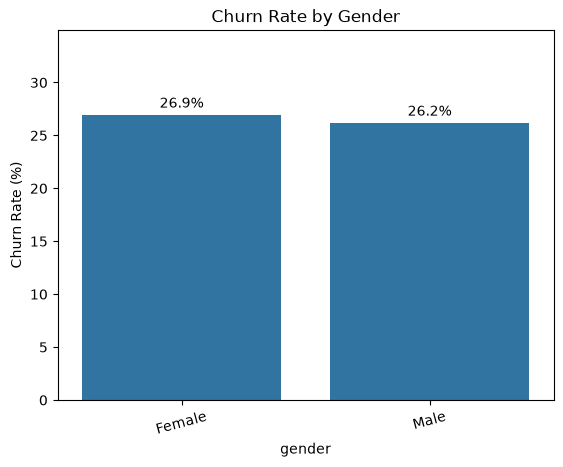

In [3]:
#Gender churn rate
print(churn_rate_by("gender"))
plot_churn_rate("gender", "Churn Rate by Gender")

**Female 26.92%, Male 26.16%, so there’s almost no difference**

              customers  churn_rate_pct
senior_label                           
Senior             1142           41.68
Non-Senior         5901           23.61


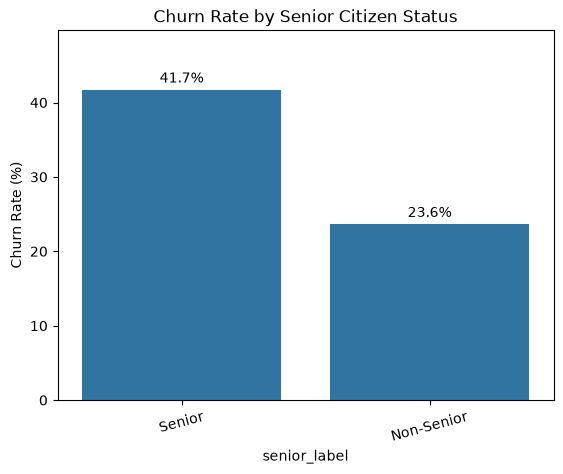

In [4]:
# Senior citizen

df["senior_label"] = df["seniorcitizen"].map({0: "Non-Senior", 1: "Senior"})
print(churn_rate_by("senior_label"))
plot_churn_rate("senior_label", "Churn Rate by Senior Citizen Status")

**Senior 41.68%, Non-Senior 23.61%. Seniors churn almost twice as much**.

                           customers  churn_rate_pct
paymentmethod                                       
Electronic check                2365           45.29
Mailed check                    1612           19.11
Bank transfer (automatic)       1544           16.71
Credit card (automatic)         1522           15.24


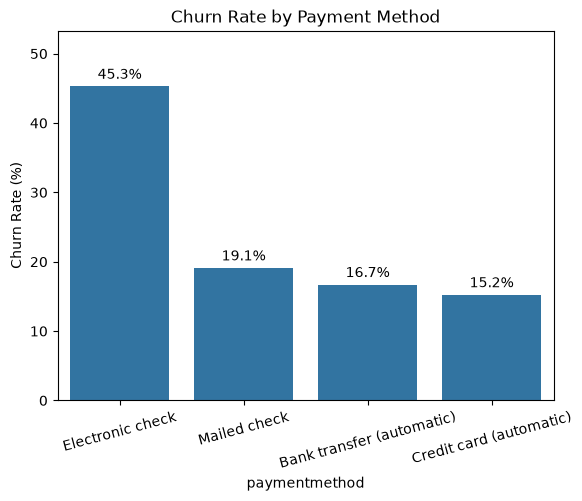

In [5]:
print(churn_rate_by("paymentmethod"))
plot_churn_rate("paymentmethod", "Churn Rate by Payment Method")

### Findings: Churn Rate by Payment Method

| Payment Method | Customers | Churn Rate |
|---|---|---|
| Electronic check | 2,365 | **45.29%** |
| Mailed check | 1,612 | 19.11% |
| Bank transfer (automatic) | 1,544 | 16.71% |
| Credit card (automatic) | 1,522 | **15.24%** |

- **Electronic check has by far the highest churn (45.29%).** Almost **1 in 2** customers who pay this way leave the company.
- It's also the **most popular** payment method (2,365 customers), so it accounts for a large share of total churn.
- **Automatic payments (bank transfer and credit card) have the lowest churn (about 15–17%).** Customers who set up auto-pay are about **3 times less likely** to leave than electronic check users.
- Mailed check sits in the middle at 19.11%.

**Insight:** Customers on automatic payments are more committed and don't have to make a monthly "pay or leave" decision. Electronic check users make a manual payment each month, which may give them more chances to rethink the service.

**Recommendation:** Encourage electronic check users to switch to automatic payment, for example with a small discount or reward for enabling auto-pay.

                customers  churn_rate_pct
contract                                 
Month-to-month       3875           42.71
One year             1473           11.27
Two year             1695            2.83


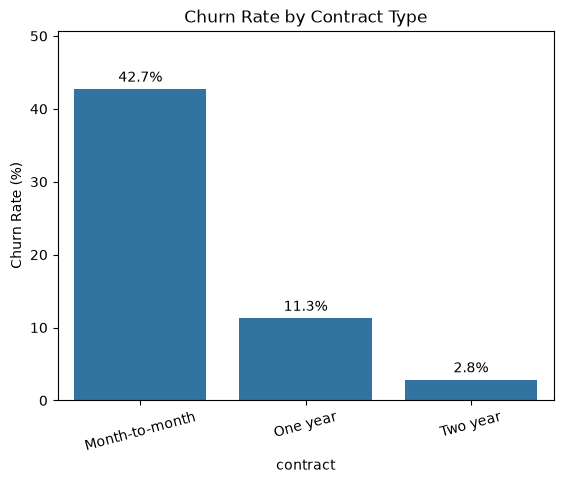

In [6]:
#churn rate by contract type
print(churn_rate_by("contract"))
plot_churn_rate("contract", "Churn Rate by Contract Type")

### Findings: Churn Rate by Contract Type

| Contract Type | Customers | Churn Rate |
|---|---|---|
| Month-to-month | 3,875 | **42.71%** |
| One year | 1,473 | 11.27% |
| Two year | 1,695 | **2.83%** |

- **Contract type has the strongest effect on churn** of all the factors analyzed.
- **Month-to-month customers have the highest churn rate (42.71%).** This is also the largest group, at more than half of all customers (3,875).
- **One-year contract customers churn far less (11.27%)**, almost **4 times lower** than month-to-month.
- **Two-year contract customers rarely leave (2.83%).** Only about 3 in 100 churn.
- **Pattern:** the longer the contract, the lower the churn.

**Insight:** Month-to-month customers can cancel at any time without a penalty, so they're the easiest to lose. Longer contracts create commitment and stability.

**Recommendation:** Offer discounts, free upgrades or loyalty rewards to move month-to-month customers onto 1-year or 2-year contracts.

### Heatmap (contract × tenure group)

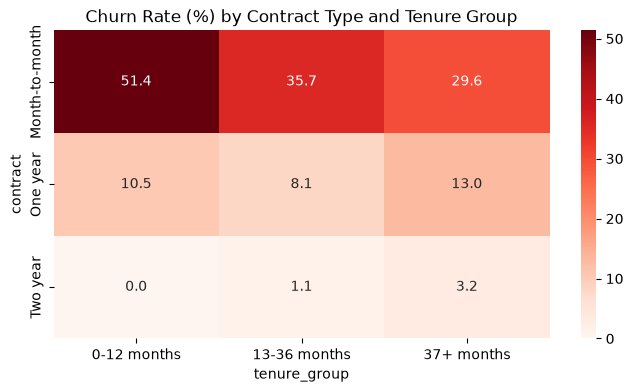

In [7]:
# Comparative analysis: churn rate by contract type and tenure group
pivot = df.pivot_table(index="contract", columns="tenure_group",
                       values="churn_flag", aggfunc="mean", observed=True) * 100

plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn Rate (%) by Contract Type and Tenure Group")
plt.show()

### Findings: Churn Rate by Contract Type and Tenure Group (Heatmap)

- **Highest risk:** month-to-month customers in their first 12 months have a churn rate of **51.4%**. More than half of them leave.
- Even long-term (37+ months) month-to-month customers still churn at **29.6%**, much higher than any contract customer.
- **One-year contracts** keep churn low (8–13%) at every tenure stage.
- **Two-year contracts** have almost no churn (0–3.2%). No new two-year customer churned.
- **Insight:** Contract type matters more than tenure. A new customer on a 2-year contract is far safer than a loyal customer on month-to-month.

                     customers  churn_rate_pct
lifecycle_stage                               
New (0-12)                2186           47.44
Growing (13-24)           1024           28.71
Established (25-48)       1594           20.39
Loyal (49-72)             2239            9.51


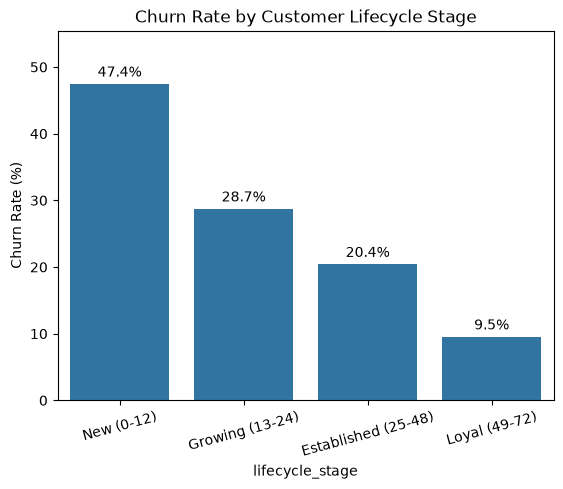

In [8]:
# Customer lifecycle stages based on tenure
df["lifecycle_stage"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                               labels=["New (0-12)", "Growing (13-24)", "Established (25-48)", "Loyal (49-72)"])
print(churn_rate_by("lifecycle_stage").sort_index())
plot_churn_rate("lifecycle_stage", "Churn Rate by Customer Lifecycle Stage")

### Findings : New 47.44%, Growing 28.71%, Established 20.39%, Loyal 9.51%

### Findings: Churn by Lifecycle Stage

- Churn falls steadily as customers stay longer: **47.44% → 28.71% → 20.39% → 9.51%**.
- **New customers (0-12 months)** are 5 times more likely to churn than **loyal customers (49-72 months)**.
- The first year is the most critical period for keeping customers.

In [9]:
%pip install "nbformat>=4.2.0"


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:
import nbformat
print(nbformat.__version__)  # should print 5.11.1

5.11.1


In [11]:
import sys
print(sys.executable)

/usr/local/bin/python3


In [12]:
import sys
!{sys.executable} -m pip install "nbformat>=4.2.0"


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


In [13]:
# Churn trend across the customer lifecycle (tenure as the timeline)
trend = df.groupby("tenure")["churn_flag"].mean().mul(100).reset_index(name="churn_rate_pct")

fig = px.line(trend, x="tenure", y="churn_rate_pct", markers=True,
              title="Churn Rate (%) by Tenure Month - Customer Lifecycle Trend",
              labels={"tenure": "Tenure (months)", "churn_rate_pct": "Churn Rate (%)"})
fig.add_annotation(x=1, y=trend.loc[trend.tenure == 1, "churn_rate_pct"].iloc[0],
                   text="Highest churn in month 1", showarrow=True, arrowhead=2)
fig.show()

In [14]:
# Part A, the tenure statistics table

tenure_stats = df.groupby("tenure_group", observed=True).agg(
    customers=("customerid", "count"),
    avg_monthly=("monthlycharges", "mean"),
    median_monthly=("monthlycharges", "median"),
    avg_total=("totalcharges", "mean"),
    churned=("churn_flag", "sum"),
    churn_rate_pct=("churn_flag", "mean"),
)
tenure_stats["churn_rate_pct"] *= 100
tenure_stats.round(2)

,customers,avg_monthly,median_monthly,avg_total,churned,churn_rate_pct
tenure_group,,,,,,
0-12 months,2186,56.10,55.90,275.23,1037,47.44
13-36 months,1856,63.25,69.68,1513.54,474,25.54
37+ months,3001,72.01,80.30,4213.72,358,11.93


### Findings: Charges and Churn Statistics by Tenure Group

| Tenure Group | Customers | Avg Monthly | Median Monthly | Avg Total | Churned | Churn Rate |
|---|---|---|---|---|---|---|
| 0-12 months | 2,186 | 56.10 | 55.90 | 275.23 | 1,037 | **47.44%** |
| 13-36 months | 1,856 | 63.25 | 69.68 | 1,513.54 | 474 | 25.54% |
| 37+ months | 3,001 | 72.01 | 80.30 | 4,213.72 | 358 | **11.93%** |

- **Churn drops sharply as tenure increases:** 47.44% → 25.54% → 11.93%. New customers are about **4 times more likely** to leave than long-term customers.
- **New customers account for most of the churn:** 1,037 of the 1,869 churned customers (**about 55%**) left within their first 12 months.
- **Monthly charges rise with tenure** (56.10 → 63.25 → 72.01). Long-term customers tend to use more services, such as fiber internet and streaming.
- **Average total charges grow rapidly** (275 → 1,514 → 4,214). Long-term customers bring in far more revenue, which makes them very valuable to keep.

**Insight:** The first year is the most critical period. If a customer stays past 12 months, they're much more likely to stay long-term and generate high revenue.

## Task 5 Summary & Recommendations

**Key findings:**
- **Gender** has almost no effect on churn (Female 26.92%, Male 26.16%).
- **Senior citizens** churn much more (41.68% vs 23.61%).
- **Electronic check** users have the highest churn (45.29%). Automatic payment users have the lowest (about 15–17%).
- **Month-to-month contracts** have the highest churn (42.71%), compared with 2.83% for two-year contracts.
- **New customers** (0-12 months) churn the most (47.44%). Churn drops to 9.51% for loyal customers.
- The **riskiest group** is new, month-to-month customers (51.4% churn).

**Recommendations:**
1. Offer discounts or rewards to move month-to-month customers onto 1- or 2-year contracts.
2. Encourage automatic payments (bank transfer or credit card) with a small incentive.
3. Run a strong onboarding and support program in the customer's first 12 months.
4. Give senior citizens dedicated support and simpler plans.